# The Harvard Forest inverse problem

This notebook introduces the inverse problem that the algorithms built in this repository
seek to solve: calibrating the SIPNET land-surface model against measurements of carbon
fluxes at Harvard Forest. Each section introduces one part of the problem, shows how to work
with it in code, and visualizes it. The full mathematical statement of the problem is in the
last section. The mathematical notation follows the repo conventions in
[`docs/notation.md`](../docs/notation.md).

Running the whole notebook takes under a minute (it runs SIPNET about 240 times).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from probpipe import (
    NumericRecordBatch,
    log_prob,
    quantile,
    sample,
    summarize,
    workflow_run,
)
from pysipnet import ClimateDrivers

from lsmas import plots
from lsmas.coordinates import inverse
from lsmas.data import load_harvard_forest
from lsmas.parameters import calibration_to_sipnet
from lsmas.problems import load_inverse_problem
from lsmas.sipnet import SIPNETSimulator

workflow_run.set_default(seed=0)  # every random call below continues one seeded stream
YEAR = 2015  # the year that the one-year figures show

The next cell defines the plotting functions this notebook uses. It is collapsed; expand it to see
how a figure is drawn.

In [2]:
from probpipe import EmpiricalDistribution

CLASS_COLOURS = {"day": "tab:orange", "night": "tab:blue"}
NEE_UNITS = "µmol m⁻² s⁻¹"


def features_in_class(data, feature_class, year=None):
    """The indices of the data values of one class (and one year, if given), in time order."""
    keep = data.feature_classes == feature_class
    if year is not None:
        keep &= data.feature_times.year == year
    rows = np.flatnonzero(keep)
    return rows[np.argsort(data.feature_times[rows])]


def daily(series):
    """Daily values of a three-hourly variable: totals over a step are summed, others averaged."""
    by_day = series.resample(time="1D")
    return by_day.sum() if series.attrs.get("kind") == "timestep_total" else by_day.mean()


def plot_weather(driver, year):
    """Daily air temperature, light, vapor pressure deficit and precipitation for one year."""
    one_year = driver.sel(time=str(year))
    panels = {
        "air temperature (°C)": daily(one_year["air_temperature"]),
        "PAR (mol m⁻² d⁻¹)": daily(one_year["photosynthetically_active_radiation"]),
        "VPD (kPa)": daily(one_year["vapor_pressure_deficit"]) / 1000,
        "precipitation (mm d⁻¹)": daily(one_year["precipitation"]),
    }
    figure, axes = plt.subplots(len(panels), 1, figsize=(9, 6.5), sharex=True)
    for axis, (label, series) in zip(axes, panels.items(), strict=True):
        axis.plot(series["time"], series, lw=0.8)
        axis.set_ylabel(label, fontsize=8)
    figure.suptitle(f"The weather at Harvard Forest, {year}")


def plot_predictions(data, predictions, labels=None):
    """The observed data (dots) and one or more predictions of them (lines), by class.

    *predictions* is one prediction, a batch of them, or a distribution of predictions held as
    draws, such as the forward model's output on a distribution of parameters; each draw is a line.
    """
    if isinstance(predictions, EmpiricalDistribution):
        predictions = predictions.atoms
    predictions = np.atleast_2d(np.asarray(predictions, dtype=float))
    times = data.feature_times
    _, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    for axis, feature_class in zip(axes, CLASS_COLOURS, strict=True):
        rows = features_in_class(data, feature_class)
        for index, prediction in enumerate(predictions):
            label = None if labels is None else labels[index]
            axis.plot(times[rows], prediction[rows], lw=0.9, alpha=0.8, label=label)
        axis.plot(times[rows], data.observations[rows], ".k", ms=3, label="observed")
        axis.axhline(0, color="0.3", lw=0.5)
        axis.set_ylabel(f"{feature_class} NEE ({NEE_UNITS})", fontsize=8)
    axes[0].legend(fontsize=7, loc="lower right")


def plot_one_at_a_time(data, predictions, parameter_names, levels, year):
    """Predictions for one year as each parameter moves through its prior quantiles."""
    times = data.feature_times
    colours = plt.cm.viridis(np.linspace(0, 1, len(levels)))
    shape = (len(parameter_names), len(levels), -1)
    predictions = np.asarray(predictions, dtype=float).reshape(shape)
    figure, axes = plt.subplots(2, len(parameter_names), figsize=(13, 5), sharex=True)
    for column, name in enumerate(parameter_names):
        for row, feature_class in enumerate(CLASS_COLOURS):
            rows = features_in_class(data, feature_class, year)
            axis = axes[row, column]
            for index, level in enumerate(levels):
                prediction = predictions[column, index, rows]
                axis.plot(times[rows], prediction, color=colours[index], label=f"{level:.1%}")
            axis.plot(times[rows], data.observations[rows], ".k", ms=3)
            axis.set_title(f"{name.rsplit('/', 1)[-1]} ({feature_class})", fontsize=7)
            axis.tick_params(labelsize=6)
    axes[0, 0].legend(fontsize=6, title="prior quantile", title_fontsize=6)
    figure.suptitle(f"One parameter at a time through its prior, the rest at their medians, {year}")
    figure.tight_layout()


def plot_sipnet_outputs(outputs, nee_rate, step_ends, year):
    """SIPNET's NEE, GPP, leaf carbon and soil wetness through one year."""
    nee = pd.Series(nee_rate, index=step_ends)[str(year)]
    one_year = outputs.sel(time=str(year))
    figure, axes = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
    axes[0].plot(nee.index, nee, lw=0.3, color="0.6", label="three-hourly")
    axes[0].plot(nee.resample("1D").mean(), lw=1, label="daily mean")
    axes[0].axhline(0, color="k", lw=0.5)
    axes[0].set_ylabel(f"NEE ({NEE_UNITS})", fontsize=8)
    axes[0].legend(fontsize=7)
    for axis, name, label in [
        (axes[1], "gross_primary_production", "GPP (g C m⁻² d⁻¹)"),
        (axes[2], "leaf_carbon", "leaf carbon (g C m⁻²)"),
        (axes[3], "soil_wetness_fraction", "soil wetness (fraction)"),
    ]:
        series = daily(one_year[name])
        axis.plot(series["time"], series, lw=1)
        axis.set_ylabel(label, fontsize=8)
    figure.suptitle(f"SIPNET at the prior medians, {year}")


def plot_averaging(data, nee_rate, averaged, year):
    """SIPNET's NEE in the windows that each data value averages, and the averages, for one year."""
    averaged = np.asarray(averaged, dtype=float)
    figure, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    for axis, (feature_class, colour) in zip(axes, CLASS_COLOURS.items(), strict=True):
        for index, row in enumerate(features_in_class(data, feature_class, year)):
            steps = data.operator[row].indices
            first = index == 0
            axis.plot(
                data.step_ends[steps],
                nee_rate[steps],
                ".",
                ms=2,
                color=colour,
                label="SIPNET, three-hourly" if first else None,
            )
            axis.hlines(
                averaged[row],
                data.step_ends[steps.min()],
                data.step_ends[steps.max()],
                color="k",
                lw=2,
                label="average, G(θ)" if first else None,
            )
        axis.axhline(0, color="0.3", lw=0.5)
        axis.set_ylabel(f"{feature_class} NEE ({NEE_UNITS})", fontsize=8)
    axes[0].legend(fontsize=7, loc="lower left")
    figure.suptitle(f"Averaging SIPNET's NEE to the data values, {year}")


def plot_residuals(data, prediction, noise_variance, widened_variance):
    """Observed minus predicted values, against two standard deviations of the noise."""
    residual = data.observations - np.asarray(prediction, dtype=float)
    noise_variance = np.asarray(noise_variance, dtype=float)
    widened_variance = np.asarray(widened_variance, dtype=float)
    times = data.feature_times
    figure, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    for axis, feature_class in zip(axes, CLASS_COLOURS, strict=True):
        rows = features_in_class(data, feature_class)
        widened = 2 * np.sqrt(widened_variance[rows])
        plain = 2 * np.sqrt(noise_variance[rows])
        axis.fill_between(times[rows], -widened, widened, color="0.88", label="±2 sd, widened")
        axis.fill_between(times[rows], -plain, plain, color="0.7", label="±2 sd")
        axis.plot(times[rows], residual[rows], ".k", ms=4, label="observed − predicted")
        axis.axhline(0, color="k", lw=0.5)
        axis.set_ylabel(f"{feature_class} ({NEE_UNITS})", fontsize=8)
        axis.legend(fontsize=7, loc="upper right", ncol=3)
    figure.suptitle("The gap between the data and G(θ) at the prior medians, against the noise")

## 1. Problem overview

SIPNET models carbon and water fluxes in a land ecosystem. Given meteorological drivers and
values of the model parameters, it predicts, among other things, the **net ecosystem exchange**
(NEE): the net flow of CO₂ from the land to the atmosphere. Harvard Forest has instruments that
measure NEE. We seek to *calibrate* the model to these measurements; roughly speaking, to tune the
model parameters so that its NEE predictions agree with the data. If $\theta$ denotes the
parameters, $y$ the NEE observations, and $G(\theta)$ SIPNET's NEE predictions, then our task is
to calibrate $\theta$ so that $y \approx G(\theta)$.

We are generally also interested in uncertainty quantification. Rather than producing a point
estimate of the parameters, we seek a distribution over the parameters that gives a score to each
possible parameter value. Formulating the parameter calibration task as a *Bayesian inverse
problem* allows us to achieve this.

At a high-level, we'll formulate the Bayesian inverse problem to look like this:
$$
\begin{align}
y &= G(\theta) + \epsilon \\
\epsilon &\sim \mathcal{N}(0, \Sigma) \\
\theta &\sim \pi_0 \\
\end{align}
$$

The model has four main pieces:
- Data: $y$, in our case 400 values of observed NEE
- Prior: $\pi_0(\theta)$ is a probability distribution encoding our knowledge about the parameters
  before seeing the data.
- Forward model: $G(\theta)$ runs SIPNET, and averages its NEE output so that each entry
  $G(\theta)_i$ is a prediction of the corresponding observation $y_i$.
- Likelihood: the first two lines in the above model define the observation model, giving the
  likelihood $p(y \mid \theta)$.

In particular, the likelihood implied by the above model is:
$$
p(y \mid \theta) = \mathcal{N}(y \mid G(\theta), \Sigma)
$$
This tells us how probable the data are if the parameters are $\theta$.

The posterior distribution is the result of updating our prior beliefs about the parameters with
the observed data. Our task is to estimate this distribution. The unnormalized density of the
posterior is the prior times the likelihood:
$$
\pi(\theta \mid y) \;\propto\; \pi_0(\theta)\, p(y \mid \theta).
$$

This Python package wraps all of the information about this inverse problem into a single object,
which is loaded as follows.

In [3]:
problem = load_inverse_problem("harvard_forest")
print(problem.describe())

harvard_forest: Harvard Forest NEE, 2012-2020, with all 46 calibration parameters (noise scales fixed).
Calibration parameters (46): photosynthetic_capacity, respiration_share, optimum_photosynthesis_temperature, photosynthesis_temperature_range, half_saturation_light, vapor_pressure_deficit_slope, vapor_pressure_deficit_exponent, light_extinction_coefficient, water_use_efficiency, water_removal_fraction, soil_water_holding_capacity, interception_evaporation_fraction, fast_flow_fraction, snow_melt_rate, aerodynamic_resistance_constant, soil_resistance_intercept, soil_resistance_slope, leaf_on_growing_degree_days, leaf_off_day, leaf_on_growth, leaf_off_fall_fraction, leaf_turnover_rate, leaf_allocation, wood_share_of_nonleaf_allocation, fine_root_share_of_root_allocation, wood_turnover_rate, fine_root_turnover_rate, coarse_root_turnover_rate, wood_respiration_rate_at_10c, wood_respiration_q10, fine_root_respiration_rate_at_10c, fine_root_respiration_q10, coarse_root_respiration_rate_at_

The attributes of this object store the inverse problem components discussed above:
`problem.data`, `problem.prior`, `problem.forward` and `problem.likelihood`. The rest of this
notebook goes through them one at a time (sections 2–5), then puts them together (section 6).
Sections 7 and 8 cover two refinements that the algorithms use, and section 9 states the problem in
full.

## 2. Harvard Forest data

The data come from the flux tower at the Harvard Forest Environmental Measurement Site
(AmeriFlux US-Ha1), in central Massachusetts. The tower's record gives NEE for every hour. The data
used here are averages of those measurements: each value is the mean NEE over the daytime (or the
night-time) hours of one half-month, from 2012 to 2020. NEE is in µmol CO₂ m⁻² s⁻¹; it is
negative when the forest takes up CO₂ and positive when it releases it.

`problem.data["nee"]` holds the 400 values, $y$:

In [4]:
y = problem.data["nee"]
y.shape

(400,)

`load_harvard_forest()` reads all of the data associated with the Harvard Forest site. Below we
print the `features` table. This prints out the NEE observations, and information about how they
were computed. Each row is one observation, computed as follows:

- The tower's hourly record is split into three-hour windows, the same steps SIPNET takes. A
  window is *usable* if all three of its hours have a value and at least two of them were measured
  rather than gap-filled.
- A window is *day* if the sun is above the horizon throughout it, and *night* if it is below
  throughout; windows containing a sunrise or sunset are dropped.
- The observation is the mean NEE over the usable day (or night) windows of one half-month: days
  1–15 or 16 to the end of the month. `n_steps` is the number of windows averaged (at least four),
  and `first_step_end_utc` and `last_step_end_utc` are the ends of the first and last of them.

In [5]:
data = load_harvard_forest()
data.features.head()

,class,year,month,half,n_steps,first_step_end_utc,last_step_end_utc,nee
0,day,2012,1,1,18,2012-01-03 18:00:00,2012-01-15 21:00:00,1.139514
1,day,2012,1,2,22,2012-01-16 21:00:00,2012-01-31 21:00:00,1.107639
2,day,2012,2,1,26,2012-02-01 21:00:00,2012-02-14 21:00:00,1.640604
3,day,2012,2,2,29,2012-02-17 15:00:00,2012-02-29 21:00:00,1.448754
4,day,2012,3,1,30,2012-03-01 18:00:00,2012-03-14 21:00:00,1.668431


In [6]:
data.features.groupby("class").size()

class
day      214
night    186
dtype: int64

We plot the NEE data below. Notice:
1. The day NEE values dip each summer. This is because plants are photosynthesizing and taking in
   lots of carbon.
2. The night values are always positive, meaning a net flux from the land to the atmosphere. This
   is because plants and soils respire (breathe out) carbon at night, without photosynthesis to
   offset it.
3. Nighttime NEE fluxes are largest in the summer, since respiration is faster when it is warm.

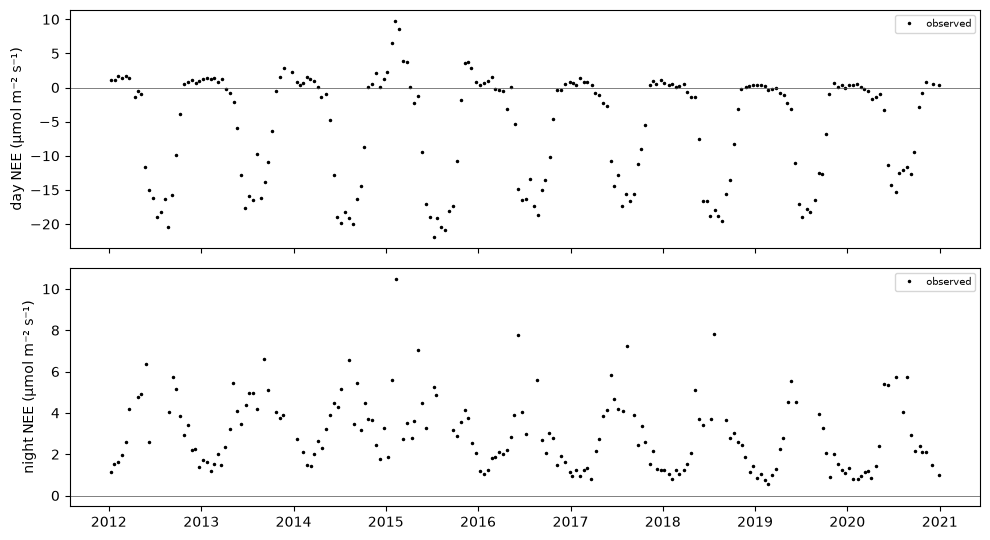

In [7]:
plots.plot_features(data);

### The weather

The SIPNET model requires weather (meteorological) data as an input. This is typically referred to
as a model *driver*: it is exogenous data that *drives* the model. SIPNET is driven by the weather
data on a 3-hourly time step. You can see the particular weather variables it requires below. The
data is stored as an [xarray](https://docs.xarray.dev/en/stable/) dataset.

In [8]:
driver = ClimateDrivers.from_path(data.driver_path, time_zone="UTC").xarray
list(driver.data_vars)

['air_temperature',
 'soil_temperature',
 'photosynthetically_active_radiation',
 'precipitation',
 'vapor_pressure_deficit',
 'soil_vapor_pressure_deficit',
 'vapor_pressure',
 'wind_speed']

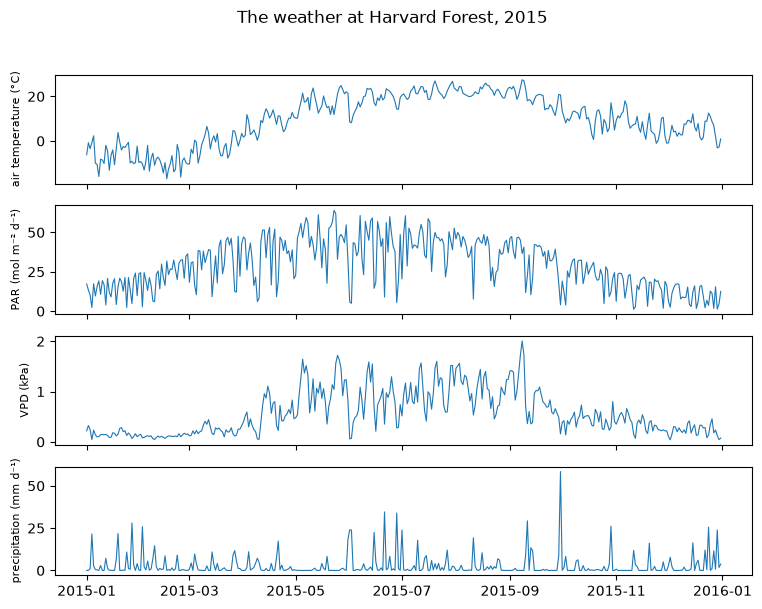

In [9]:
plot_weather(driver, YEAR)

## 3. The prior

SIPNET has a bunch of parameters. The inverse problem returned by `load_inverse_problem` defines a
prior distribution on 46 parameters. This set of parameters was assembled by (1) fixing parameters
that do not affect NEE in the model configuration used here (e.g., those of the litter pool, which
is switched off) and (2) manually eliminating some exact nonidentifiability. This still leaves a
large number of parameters, a prime candidate for data-driven parameter reduction algorithms.

The prior distribution of each individual parameter is stored in `data.prior_table`.

In [10]:
data.prior_table.head(10)

,units,family,lower,upper,mean,sd,source
parameter,,,,,,,
photosynthetic_capacity,nmol g-1 s-1,log_normal,140.00,450.00,NaN,NaN,P2
respiration_share,1,logit_normal,0.04,0.20,NaN,NaN,P2
optimum_photosynthesis_temperature,degC,normal,NaN,NaN,22.0,2.5,P2
photosynthesis_temperature_range,degC,log_normal,17.00,31.00,NaN,NaN,"BETY psnTMin 2.5-97.5% (-6.5, 6.6) below psnTO..."
half_saturation_light,mol m-2 d-1,log_normal,4.60,26.30,NaN,NaN,BETY
vapor_pressure_deficit_slope,kPa-1,log_normal,0.02,0.12,NaN,NaN,BETY median 0.050; R interval
vapor_pressure_deficit_exponent,1,log_normal,1.00,3.00,NaN,NaN,"Niwot range [1, 3]; BETY 1.5, Braswell 2"
light_extinction_coefficient,1,log_normal,0.38,0.65,NaN,NaN,BETY attenuation widened by BETY leafCSpWt spr...
water_use_efficiency,mg g-1 kPa,log_normal,7.90,17.50,NaN,NaN,BETY


Most priors are log-normal, parameterized by the interval that holds 95% of their probability
(`lower` and `upper`). Section 9 gives more details.

### Sampling the prior

`problem.prior` stores a ProbPipe distribution representing the object $\pi_0(\theta)$. We show how
to manipulate this object below.

In [11]:
prior = problem.prior
print(prior)

prior(theta)


Let's draw some samples from the prior. Observe that the parameters are all grouped under "theta".
The reason for this is that the more general inverse problem we will consider later will contain
another group of parameters as well. The code below shows how to access the values of particular
parameters.

In [12]:
prior_draws = sample(prior, 2000)
print(prior_draws)

theta/photosynthetic_capacity                 [273.24845094 422.9131429
                                               179.3635181  ...
                                               275.13365543 130.87320383
                                               284.06177026]   shape=(2000,)
theta/respiration_share                       [0.05692348 0.08883427
                                               0.08286174 ... 0.05057712
                                               0.0646365  0.12234828]   shape=(2000,)
theta/optimum_photosynthesis_temperature      [15.36836662 15.55881094
                                               22.99698598 ... 22.21966791
                                               23.11020984 23.84667298]   shape=(2000,)
theta/photosynthesis_temperature_range        [34.52357536 31.0846502
                                               22.30428108 ... 22.90038253
                                               21.24348732 13.29723387]   shape=(2000,)
theta/half_saturati

In [13]:
prior_draws["theta/photosynthetic_capacity"]

NumericArrayBatch(
    'theta/photosynthetic_capacity',
    levels={'sample': 2000},
    element=NumericArraySpec(shape=(), dtype=float64, support=positive),
)
  [273.24845094 422.9131429  179.3635181  ... 275.13365543 130.87320383
   284.06177026]

The raw array can be extracted from the ProbPipe object using `.raw`.

In [14]:
prior_draws["theta/photosynthetic_capacity"].raw

Array([273.24845094, 422.9131429 , 179.3635181 , ..., 275.13365543,
       130.87320383, 284.06177026], dtype=float64)

The `plots` module of this package provides a function for visualizing one-dimensional marginal
distributions. It takes any number of ProbPipe distributions, or samples from them, and draws
those that share a parameter on the same panel. Here the prior's exact densities are drawn over a
histogram of the samples.

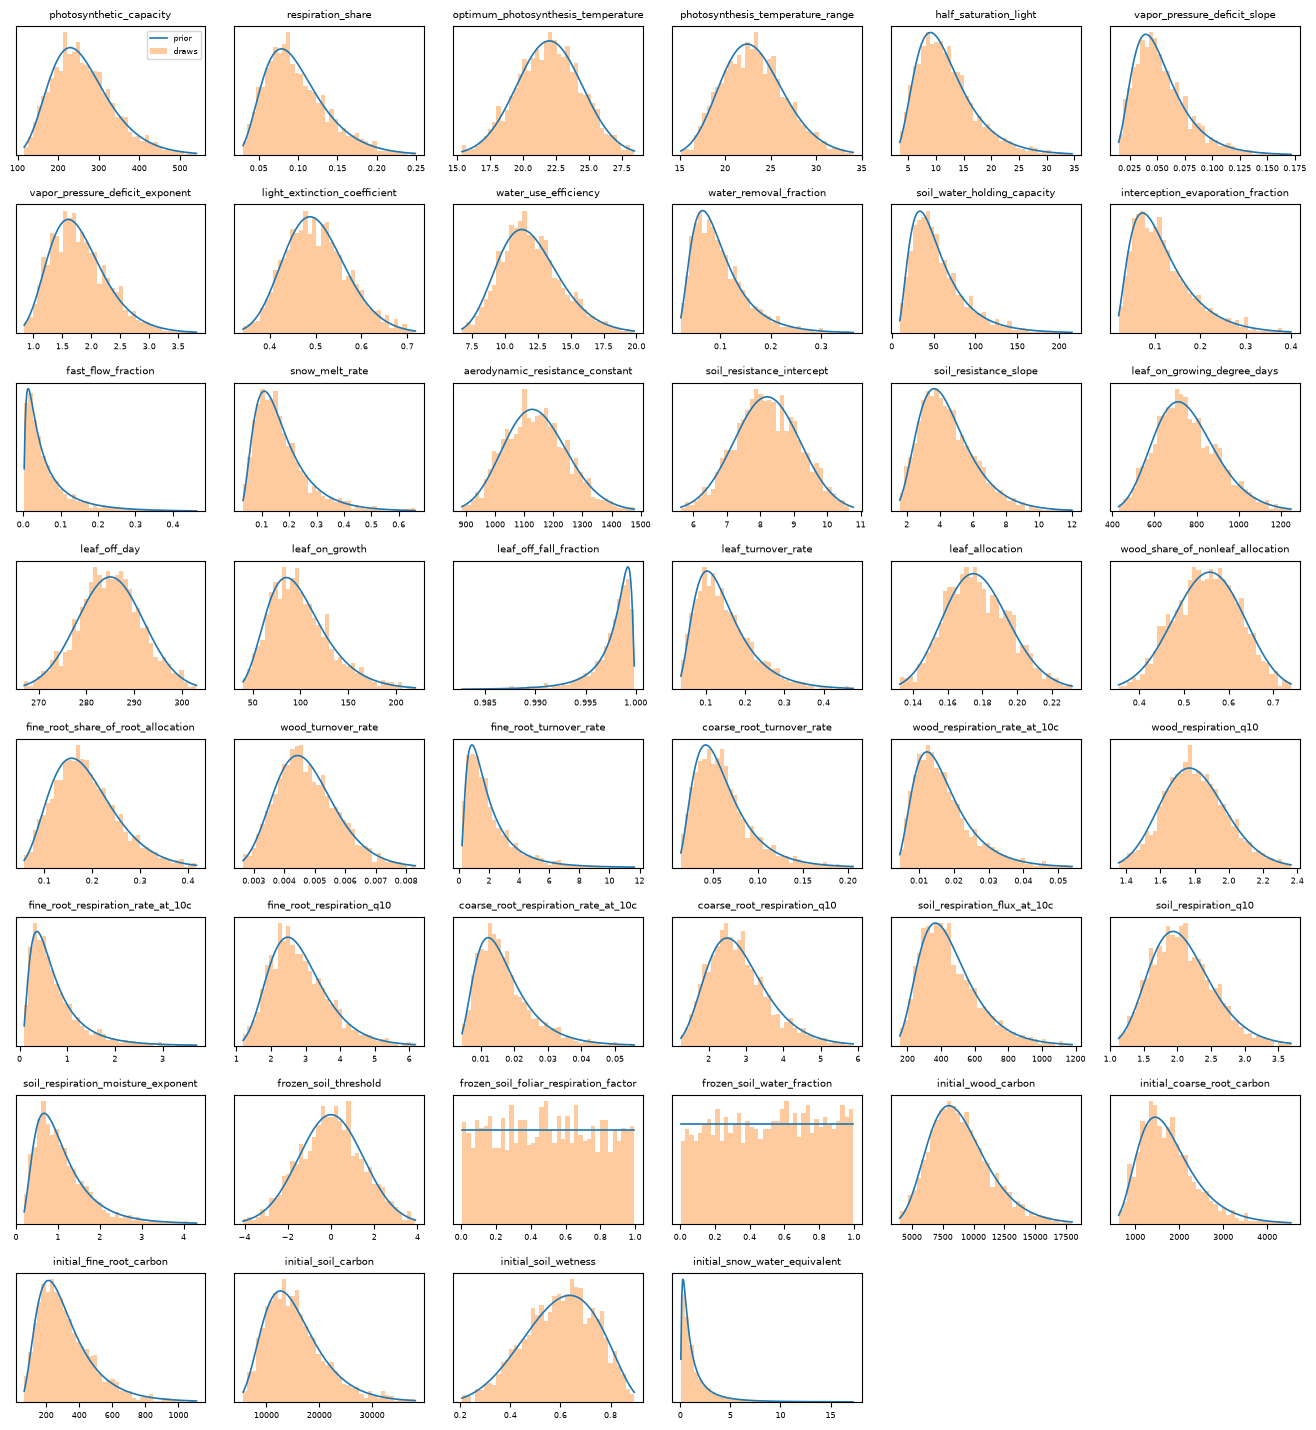

In [15]:
plots.plot_marginals(prior, prior_draws);

ProbPipe's `summarize` command also gives a quick numeric summary of each marginal.

In [16]:
summarize(prior)

,mean,sd,median,q10,q90
theta/photosynthetic_capacity,2.64671186e+02,7.99465871e+01,2.50998008e+02,1.71351502e+02,3.67665292e+02
theta/respiration_share,1.00471303e-01,4.05779303e-02,9.26100944e-02,5.37604157e-02,1.54937363e-01
theta/optimum_photosynthesis_temperature,2.18362365e+01,2.60846664e+00,2.20000000e+01,1.87961211e+01,2.52038789e+01
theta/photosynthesis_temperature_range,2.31552847e+01,3.57384988e+00,2.29564806e+01,1.88627262e+01,2.79386974e+01
theta/half_saturation_light,1.24009725e+01,5.64265164e+00,1.09990909e+01,6.22019840e+00,1.94495404e+01
theta/vapor_pressure_deficit_slope,5.33510613e-02,2.49814938e-02,4.89897949e-02,2.72711055e-02,8.80052332e-02
theta/vapor_pressure_deficit_exponent,1.80061974e+00,5.15262582e-01,1.73205081e+00,1.20941184e+00,2.48054458e+00
theta/light_extinction_coefficient,5.00257699e-01,6.96519987e-02,4.96990946e-01,4.16994953e-01,5.92333309e-01
theta/water_use_efficiency,1.19395169e+01,2.53319639e+00,1.17579760e+01,9.06580821e+00,1.52496056e+01
theta/water_removal_fraction,1.01476845e-01,6.45109291e-02,8.66025404e-02,4.32997233e-02,1.73211268e-01


### Prior Density

The below code samples from the prior. Then it evaluates the prior log-density at those samples.

In [17]:
samples = sample(prior, 5)
log_density_at_samples = log_prob(prior, samples)

log_density_at_samples

NumericArrayBatch(
    'log prior(theta)',
    levels={'sample': 5},
    element=NumericArraySpec(shape=(), dtype=float64),
)
  [-60.95878463 -53.25957122 -58.14119513 -66.50670036 -56.46359081]

## 4. The forward model

The forward model $G$ maps parameters $\theta$ to predictions of the data $y$. It thus involves
first running SIPNET, and then averaging SIPNET's output to produce a quantity comparable to the
data. In the inverse problems literature, $G$ is sometimes referred to as the
*parameter-to-observable* map.

The inverse problem stores the forward model as `problem.forward`. Under the hood, `forward` is a ProbPipe `Function`. The `input_spec` shows the form of the argument that this function expects.

In [18]:
forward_model = problem.forward

forward_model.input_spec

InputSpec(
    theta=NumericRecordSpec(
        photosynthetic_capacity=(),
        respiration_share=(),
        optimum_photosynthesis_temperature=(),
        photosynthesis_temperature_range=(),
        half_saturation_light=(),
        vapor_pressure_deficit_slope=(),
        vapor_pressure_deficit_exponent=(),
        light_extinction_coefficient=(),
        water_use_efficiency=(),
        water_removal_fraction=(),
        soil_water_holding_capacity=(),
        interception_evaporation_fraction=(),
        fast_flow_fraction=(),
        snow_melt_rate=(),
        aerodynamic_resistance_constant=(),
        soil_resistance_intercept=(),
        soil_resistance_slope=(),
        leaf_on_growing_degree_days=(),
        leaf_off_day=(),
        leaf_on_growth=(),
        leaf_off_fall_fraction=(),
        leaf_turnover_rate=(),
        leaf_allocation=(),
        wood_share_of_nonleaf_allocation=(),
        fine_root_share_of_root_allocation=(),
        wood_turnover_rate=(),
     

$G$ depends on $\theta$ alone. Under the hood, the meteorological drivers are also being fed to SIPNET when the function is called; the `forward` interface makes it so you don't have to deal with that.

The below code evaluates this map at $G(\theta_{\mathrm{median}})$ where $\theta_{\mathrm{median}}$
contains the prior median of each parameter. It runs SIPNET once. We see that the output is an array with length 400, as we expect (one prediction for each observation in $y$). 

In [19]:
prior_medians = quantile(prior, 0.5)

prediction_at_medians = forward_model(prior_medians["theta"])
prediction_at_medians

NumericArray('nee_features(theta)', shape=(400,), dtype=float64)
  [  0.88267853   0.84728729   0.92151995   0.87138089   1.00961978
     1.48687006   1.57473494   1.84525016  -6.59197779 -13.1309674
   -15.83881899 -11.95456408 -10.10570557 -13.72969839 -13.49714408
   -10.69158827 -14.32362524 -15.9938552   -6.3259913    1.25450847
     1.10502762   0.84027913   0.79145557   0.72258866   0.78281216
     0.73203216   0.70505072   0.69637811   0.83494214   0.84828461
     1.07295024   1.42143696   1.87159648  -3.0657661  -11.44389535
   -14.58807687 -13.47727862 -12.30233204 -14.15637383 -16.51996472
   -19.0946365  -22.2547321  -13.20009127   0.91296382   0.86897367
     0.84846992   0.81907942   0.78631625   0.72904952   0.65622716
     0.66913971   0.67924704   0.70996061   1.26155236   1.30134972
     1.78124224   0.22542129 -12.83023417 -13.02385641 -14.01152446
   -17.82018415 -20.96339277 -21.16618543 -16.5887255  -15.96503758
   -10.95266582   1.01533728   0.93678417   0.740328

Let's plot the model prediction against the observed data. We see that the predictions capture the general seasonality, but overall the predictions have a lot of room for improvement. This is why we want to calibrate the parameters. 

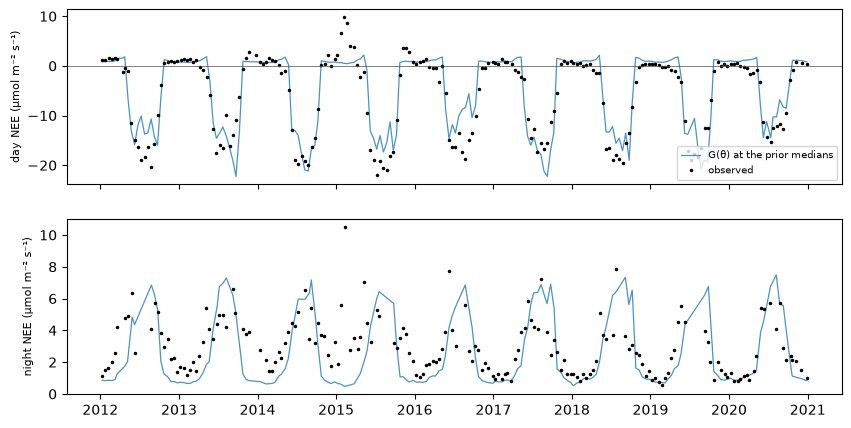

In [20]:
plot_predictions(data, prediction_at_medians, labels=["G(θ) at the prior medians"])

### Ensemble runs: running the forward model at multiple parameter settings

The forward model also conveniently accepts a batch of parameter settings. This allows running ensembles of forward model runs with a single function call. If you run it at many parameter values, expect this to take a little while since SIPNET must be run once per value.

Below, we draw multiple samples from the prior and then evaluate the forward model on each sample. The output is a sample of the model's predictions $G(\theta)$ under the prior: the *prior predictive distribution* without the observation noise $\epsilon$ (section 6 adds the noise).

In [21]:
prior_samples = sample(prior, 8)
predictions = forward_model(prior_samples["theta"])
predictions

NumericArrayBatch(
    'nee_features(theta)',
    levels={'sample': 8},
    element=NumericArraySpec(shape=(400,), dtype=float64),
)
  [[0.85569709 0.8097936  0.87437655 ... 1.2047427  1.11990496 0.8539181 ]
   [1.22872621 1.18367927 1.31823606 ... 1.50924752 1.18297845 0.87585905]
   [1.52766343 1.48327838 1.54891255 ... 1.87799387 1.62589456 1.29688811]
   ...
   [0.70023261 0.64965701 0.72167939 ... 0.82443288 0.64054639 0.41450608]
   [0.72164645 0.72184112 0.78661275 ... 1.23557863 1.01688491 0.80351321]
   [1.83045514 1.82387525 1.88810779 ... 2.09470194 1.74433257 1.51866961]]

Let's once again plot these predictions.

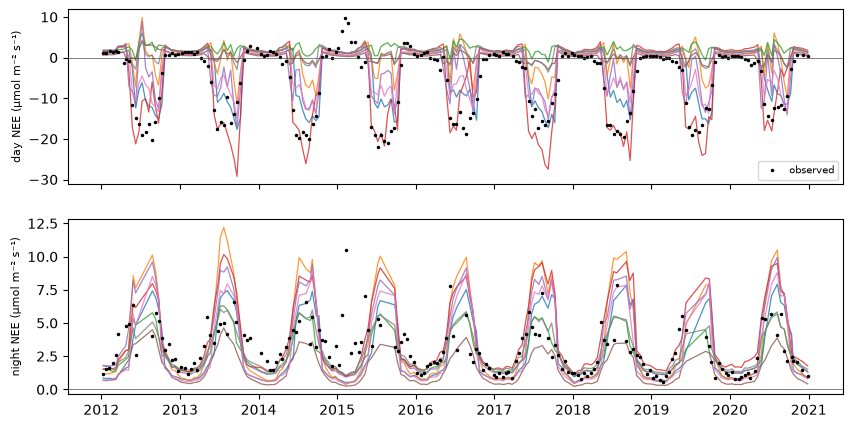

In [22]:
plot_predictions(data, predictions)

ProbPipe will even do this sampling step for you. If you directly pass `prior["theta"]` to the forward model, 
it will:
1. Sample from the prior `max_evaluations` times.
2. Then run the forward model at the samples.

Thus, the following is an equivalent way to draw samples of the predictions under the prior. The result is the distribution over $G(\theta)$. 

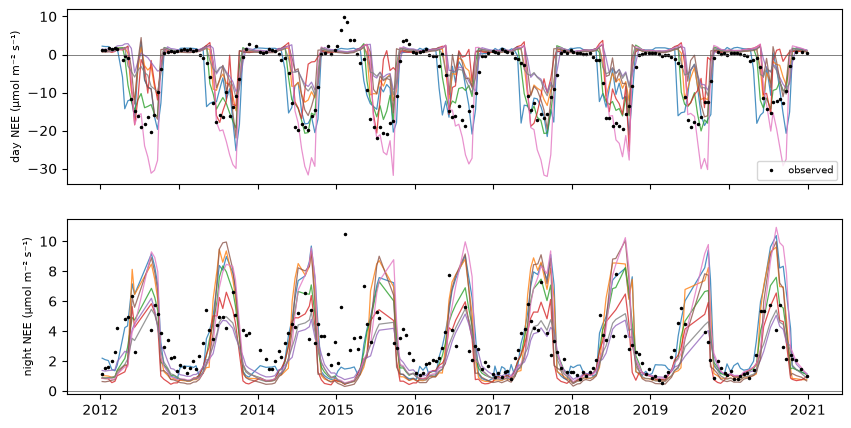

In [23]:
predictions = forward_model.using(max_evaluations=8)(prior["theta"])
plot_predictions(data, predictions)

### Varying parameters one at a time

A useful (though painstaking) exercise is to vary parameters individually, while holding all others constant, in order
to see their effect. The below code shows one way to go about this. We choose some parameters to vary and individually vary each of them at different values of their quantiles under the prior.

In [24]:
# vary these parameters across the specified prior quantiles
varied_names = [
    "theta/photosynthetic_capacity",
    "theta/soil_water_holding_capacity",
    "theta/leaf_on_growing_degree_days",
    "theta/soil_respiration_flux_at_10c",
]
levels = np.array([0.025, 0.25, 0.5, 0.75, 0.975])

# the quantiles of the varied parameters, all at once
varied_quantiles = quantile(prior[varied_names], levels)

# one parameter setting per parameter and level, with every other parameter at its prior median
settings = NumericRecordBatch.stack(
    [
        prior_medians.replace({name: value})
        for name in varied_names
        for value in varied_quantiles[name]
    ],
    level_name="setting",
)

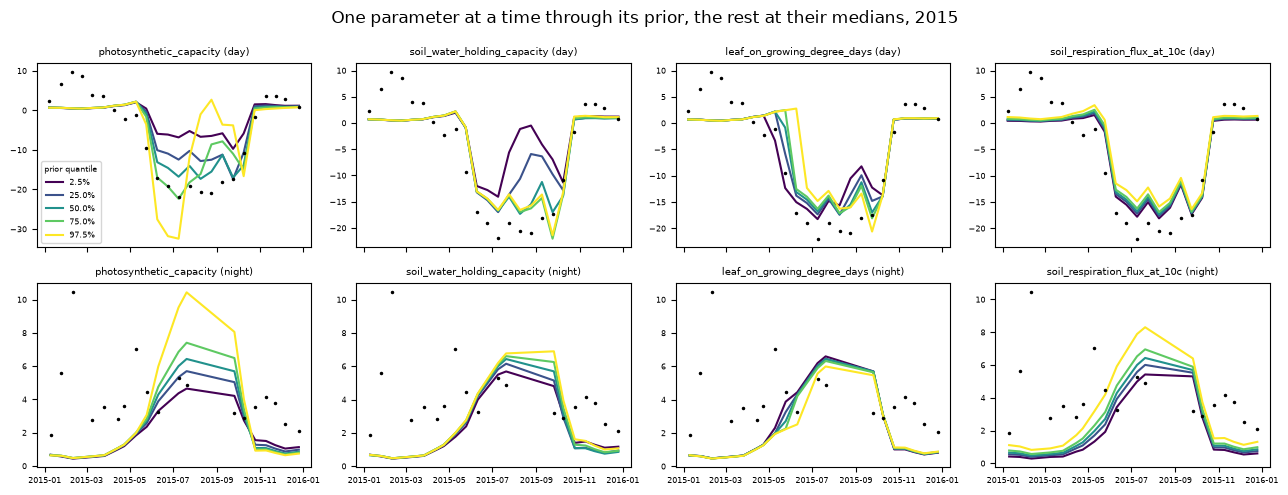

In [25]:
varied_predictions = forward_model(settings["theta"])

plot_one_at_a_time(data, varied_predictions, varied_names, levels, YEAR)

### Under the hood of the forward model

For most use cases in this project, running the forward model should be sufficient. However, it may be useful to better understand how things work under the hood. We provide some additional details here. 

When you call `problem.forward()` on a single parameter input, the following steps are run:
1. The function `calibration_to_sipnet` converts the parameters we use in calibration to the parameterization that SIPNET requires.
2. Create an object `SIPNETSimulator` that fixes the driver data and the fixed SIPNET parameters.
3. Call `SIPNETSimulator.run()` to evaluate the simulator at the non-fixed parameters and return SIPNET's outputs.
4. Extract NEE from the outputs and convert the units to agree with the observations $y$.
5. Average the NEE to the data's resolution


The below code applies these steps by hand.

In [26]:
# 1. convert to SIPNET's parameter set (which depends on some parameters that we have fixed in
#    the inverse problem setup)
sipnet_parameters = calibration_to_sipnet(prior_medians["theta"], data.fixed_sipnet_parameters)

# 2. define the SIPNET simulator by specifying the filepath to the driver data and providing the
#    fixed parameters
simulator = SIPNETSimulator(data.driver_path, data.fixed_sipnet_parameters)

# 3. run the model
outputs = simulator.run(sipnet_parameters)

# the result is an xarray dataset with SIPNET's output at a 3-hourly time step
outputs

<xarray.Dataset> Size: 12MB
Dimensions:                            (time: 37992, bounds: 2)
Coordinates:
  * time                               (time) datetime64[ns] 304kB 2012-01-01...
    timestep_start                     (time) datetime64[ns] 304kB 2011-12-31...
    timestep_length                    (time) timedelta64[ns] 304kB 03:00:00 ...
    year                               (time) int64 304kB 2011 2012 ... 2024
    day_of_year                        (time) int64 304kB 365 1 1 ... 366 366
    hour_of_day                        (time) float64 304kB 21.0 0.0 ... 18.0
    time_bounds                        (time, bounds) datetime64[ns] 608kB 20...
Dimensions without coordinates: bounds
Data variables: (12/32)
    wood_carbon                        (time) float64 304kB 8.66e+03 ... 1.15...
    leaf_carbon                        (time) float64 304kB 0.0 0.0 ... 0.0 0.0
    wood_growth                        (time) float64 304kB 0.0 -0.0 ... -0.03
    soil_carbon                        (time) float64 304kB 1.449e+04 ... 1.5...
    coarse_root_carbon                 (time) float64 304kB 1.673e+03 ... 2.8...
    fine_root_carbon                   (time) float64 304kB 282.7 ... 39.72
    ...                                 ...
    nitrogen_volatilization            (time) float64 304kB 0.0 0.0 ... 0.0 0.0
    nitrogen_leaching                  (time) float64 304kB 0.0 0.0 ... 0.0 0.0
    nitrogen_fixation                  (time) float64 304kB 0.0 0.0 ... 0.0 0.0
    nitrogen_uptake                    (time) float64 304kB 0.0 0.0 ... 0.0 0.0
    methane_production                 (time) float64 304kB 0.0 0.0 ... 0.0 0.0
    wood_storage_carbon                (time) float64 304kB -0.0509 ... -1.169
Attributes:
    Conventions:             CF-1.11
    source:                  SIPNET output, via pySIPNET
    time_convention:         The 'time' coordinate is the END of each timeste...
    time_zone:               UTC
    time_axis_source:        climate drivers
    timestep_length_source:  climate drivers
    run_id:                  50d0335a6b134edbbccf84a1bc043f26
    model_flags:             {"anaerobic": false, "carbon_saturation": false,...

In [27]:
# 3. and 4. in one step: run the model, extract NEE, convert units
nee = simulator.nee_rate(sipnet_parameters)

# 5. average NEE to the data's resolution
A = data.operator
nee_avg = A @ nee

# the steps by hand give the forward model's predictions
np.allclose(nee_avg, prediction_at_medians)

True

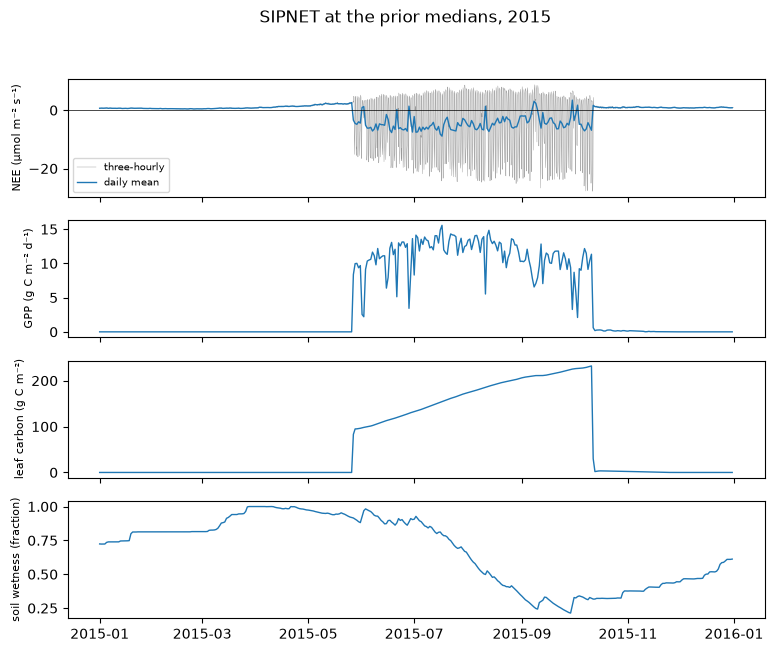

In [28]:
# SIPNET outputs
plot_sipnet_outputs(outputs, nee, data.step_ends, YEAR)

The below plot visualizes how the NEE values are averaged. The averaging is determined by the data. Roughly, the procedure followed is:
1. Define day and night windows.
2. If any window does not have enough observations, drop it.
3. Average the observations within each window.
4. Compute half-monthly averages of all daytime window averages. Do the same for nighttime.

To clarify, suppose $y_i$ is a daytime value in the first half of January, 2015. This means that is was constructed by averaging the window averages for all (non-dropped) daytime windows within that time frame. 

The corresponding output $G_i(\theta)$ is thus computed in the same way, by repeating steps 3 and 4 to average SIPNET's NEE predictions in the same way that the data was averaged.

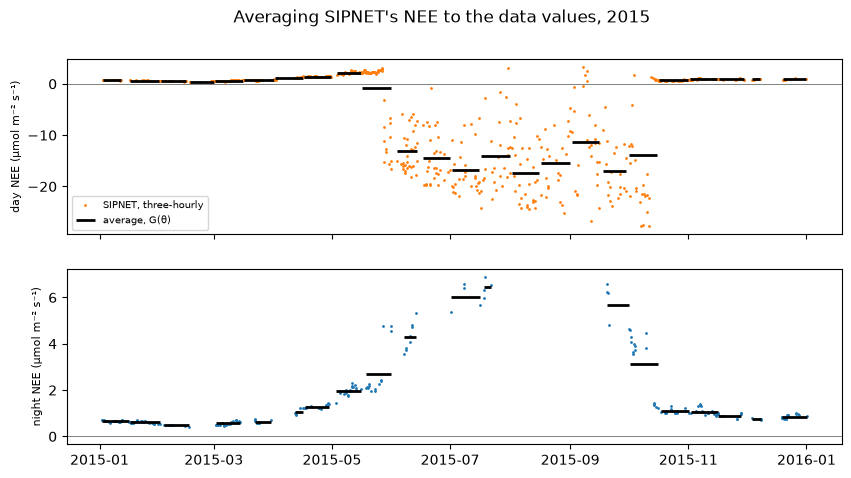

In [29]:
plot_averaging(data, nee, nee_avg, YEAR)

## 5. The likelihood

We never expect the model predictions to match the data exactly. There are many sources of discrepancy between the measurements and the model predictions. Here we keep things simple and assume that the gap between the model predictions and data can be described by Gaussian noise:

$$
y_i = G_i(\theta) + \epsilon_i, \qquad \epsilon_i \sim \mathcal N(0, \sigma_i^2),
$$

independently for each value $i$, so that $\Sigma = \operatorname{diag}(\sigma_1^2, \dots, \sigma_n^2)$. The standard deviation $\sigma_i$ of the noise is the same for all day values, and the same for all night values.

Below we extract the likelihood from the inverse problem object and look at the noise standard deviations $\sigma_i$.

In [30]:
likelihood = problem.likelihood

# feature_classes simply flags each value as "day" or "night"
noise_sd = np.sqrt(likelihood.noise_variances())
pd.Series(noise_sd).groupby(data.feature_classes).first()

day      2.828427
night    1.224745
dtype: float64

Since the likelihood depends on SIPNET, evaluating it at one parameter value means running SIPNET one time. So, once again, expect things to take a while if you are trying to evaluate the likelihood many times.

Mathematically, the log likelihood evaluation is computing the following:
$$
\log p(y \mid \theta) = \sum_{i=1}^{400} \log \mathcal N\!\left(y_i \mid G_i(\theta), \sigma_i^2\right).
$$

The `likelihood` is a ProbPipe `ConditionalDistribution` under the hood. Below we evaluate it at $\theta_{\mathrm{median}}$. 

In [31]:
log_likelihood_at_median = log_prob(likelihood, y, given=prior_medians)
log_likelihood_at_median

NumericArray('log nee_likelihood(nee; theta)', shape=(), dtype=float64)
  -997.42277062

### The learning rate

There's one more element we've been ignoring up to this point. To motivate this, note that our assumption that the observation noise is independent across time is certainly wrong. Treating the observations as independent over-inflates the amount of information contained in the data, which would make the posterior overly confident.

In an effort to correct for this, we adopt the simple approach of raising each term in the likelihood by a power $\eta_i < 1$ referred to as the *learning rate*, which has the effect of reducing the impact of the data on the posterior. 

The value of $\eta_i$ is chosen so that the data count as much as about three independent values per year per class (day/night label). These values are fixed throughout the analysis.

The below residual plot clearly demonstrates the correlation in the observations.

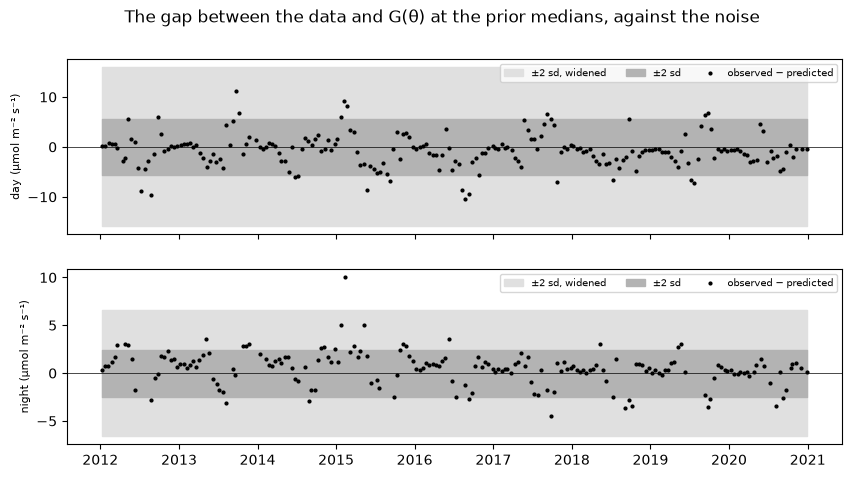

In [32]:
plot_residuals(data, prediction_at_medians, likelihood.noise_variances(), problem.noise_variance())

In [33]:
eta = problem.learning_rate["nee"]

print("Learning rates:")
pd.Series(eta).groupby(data.feature_classes).first()

Learning rates:


day      0.126168
night    0.137097
dtype: float64

Raising a Gaussian log-likelihood by $\eta_i$ has the same effect as dividing the
noise variance by $\eta_i$. So the learning rate effectively increases the noise.
`problem.noise_variance()` gives the widened variances, $\sigma_i^2 / \eta_i$:

In [34]:
effective_sd = np.sqrt(problem.noise_variance())
pd.Series(effective_sd).groupby(data.feature_classes).first()

day      7.962877
night    3.307745
dtype: float64

So why not just treat $\eta_i$ as part of the variance and forget about this "learning rate"? If we were always to assume that the noise variances are known/fixed, then this would be a perfectly fine thing to do. However, as we will shortly show, the real inverse problem we hope to solve also treats the variances $\sigma_i^2$ as unknown. If we parameterized the variances as $\sigma_i^2 / \eta_i$ and learn $\sigma_i$, then the learned values of $\sigma_i$ will simply adjust to whatever scale $\eta_i$ sets. In other words, $\eta_i$ won't have any effect. This is the reason we need to treat $\eta_i$ in the way we do, to make sure it dampens the influence of the data, regardless of how we choose $\sigma_i$. 

## 6. The full Bayesian model

The full Bayesian model is given by the joint distribution
$$
p(\theta, y) = \pi_0(\theta) p(y \mid \theta),
$$
combining the likelihood and the prior. Drawing one sample from this distribution can be done in two stages:
1. Sample $\theta$ from the prior: $\theta^\prime \sim \pi_0$
2. Sample $y$ from the observation model given $\theta^\prime$: $y^\prime \sim p(y \mid \theta^\prime)$

A value $y^\prime$ computed in this way is a prior predictive sample (this time incorporating the observation noise as well). The below code runs this procedure to generate multiple such samples. Since each draw runs SIPNET, this will take a bit of time.

In [35]:
model_samples = sample(problem.model, 200)
nee_samples = model_samples["nee"]

We now plot these samples against the observed data. What we hope to see is that the prior at least covers the data.

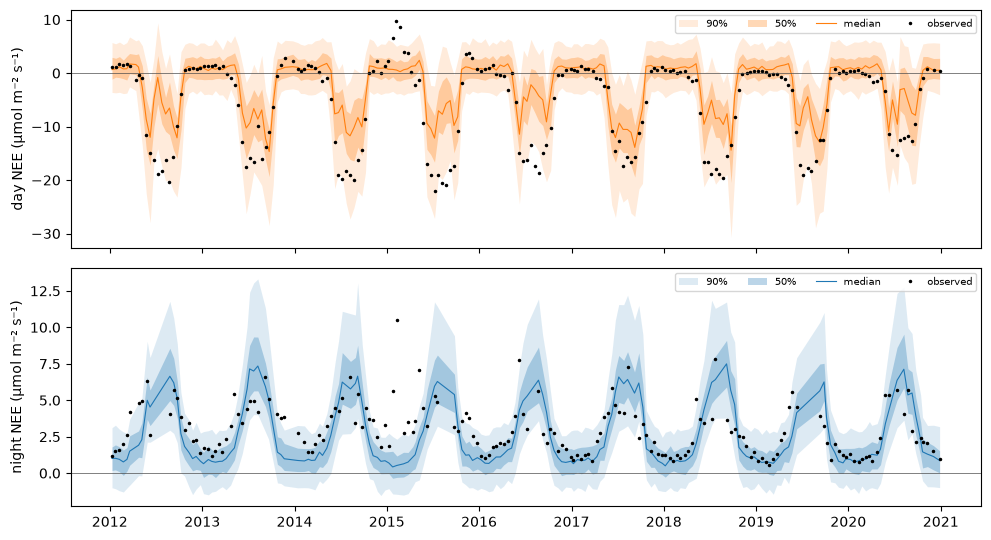

In [36]:
plots.plot_features(data, nee_samples);

### The goal: estimate the posterior

The goal of the algorithms in this repo is to estimate the posterior $\pi(\theta \mid y)$ by conditioning on the observed data. This is the hard part. Once we obtain $\pi(\theta \mid y)$
we can generate the same predictions as above using the posterior in place of the prior to see how much they improve.

#### Clarification: where the learning rate comes in
One subtlety to note is that the posterior considered in this project is not the typical Bayesian posterior. It is a "generalized Bayesian posterior" due to the introduction of the learning rates $\eta_i$. The learning rates played no part in the prior predictions above. They come into play when we define the density of the target distribution. The Harvard Forest inverse problem defines this density as:
$$
\log \pi(\theta \mid y) = \log \pi_0(\theta)
+ \sum_{i=1}^{400} \eta_i \log \mathcal N\!\left(y_i \mid G_i(\theta), \sigma_i^2\right)
+ \text{const}.
$$

Setting $\eta_i = 1$ recovers the standard Bayesian posterior. In most cases you won't need to think too much about this. The method `problem.condition()` automatically includes the learning rate.


#### Why this is hard
Estimating the posterior is the core challenge in Bayesian inference. A few things make it especially challenging in this setting:
1. $\theta$ is fairly dimensional, containing 46 parameters.
2. Many of the parameters are quite correlated in the posterior.
3. Typical posterior approximation algorithms like MCMC require evaluating the density $p(\theta, y)$ many times. With each evaluation requiring a call to SIPNET, the runtime adds up quickly.
4. SIPNET does not provide gradients, so standard gradient-based posterior inference algorithms cannot be applied.

#### The solutions
The algorithms in this repo seek to address these challenges in a few different ways:
1. Gradient-free methods
2. Methods that run SIPNET evaluations in parallel and generally utilize as few evaluations as possible
3. Algorithms that learn a reduced subspace which captures most of the parameter variation in the posterior. This addresses the high-dimensionality and correlation challenges mentioned above.

## 7. Learning noise scales

So far we have considered the noise variance $\sigma_i^2$ to be fixed. We can extend our previous formulation to try to learn these parameters as well. The Harvard forest inverse problem with `scales="inferred"` does exactly this. This model uses the parameterization,
$$
\epsilon_i \sim \mathcal N\!\left(0,\; s^2_{k(i)}\, \sigma^2_i\right)
$$
with the $\sigma_i^2$ remaining at their previous values, but the scales $s^2_{k(i)}$ now treated as unknown. Here $k(i)$ denotes either day or night, allowing the scales to differ across these two.

The full probability model is now:
$$
p(\theta, s, y) = \pi_0(\theta, s) p(y \mid \theta, s)
$$
and we must learn the joint posterior $p(\theta, s \mid y)$. The model is defined to be an extension of the previous model.

Let's load the inverse problem with `scales="inferred"`. Its
prior is now over both $\theta$ and $s^2$: the scales are grouped under `s2`, as the parameters
are under `theta`, with one field per class, `s2/day` and `s2/night`. The model assumes independent inverse Gamma priors on each, each with median $1$. The prior on $\theta$ is unchanged. 

In [37]:
problem_with_scales = load_inverse_problem("harvard_forest", scales="inferred")
prior_with_scales = problem_with_scales.prior

# sample the s^2 portion of the prior
sample(prior_with_scales["s2"], 4)

path,value
day,[1.05397327 0.56516397 0.61570016 0.79651773]
night,[1.1686154 0.89265778 1.10953299 0.59928443]


In [38]:
# verify medians are (about) 1
quantile(prior_with_scales["s2"], 0.5)

path,value
day,0.99979325
night,0.99979325


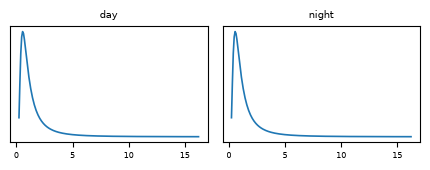

In [39]:
# plot prior marginals
plots.plot_marginals(prior_with_scales["s2"], columns=2);

The likelihood now needs the scales as well as $\theta$: its given values are the records
`theta` and `s2`.

In [40]:
likelihood_with_scales = problem_with_scales.likelihood
medians_with_scales = quantile(prior_with_scales, 0.5)

log_prob(likelihood_with_scales, y, given=medians_with_scales)

NumericArray('log nee_likelihood(nee; theta, s2)', shape=(), dtype=float64)
  -997.45785415

## 8. Additional details: coordinates

The inverse problem interface introduced above works in the natural coordinates of the parameters.
Most inference algorithms benefit from working in unconstrained coordinates. Moreover, active
subspace algorithms benefit from working in unconstrained whitened coordinates (i.e., z-scores, so
that the whitened prior has mean zero and unit variances). In summary, there are three different
coordinate systems in play:
1. constrained/natural: $\theta$, each parameter in its original units and range
2. unconstrained: denoted $\phi$, each parameter mapped to the whole real number line
3. whitened: denoted $z$, the shifted and scaled version of $\phi$ so that, under theprior, 
$z$ has mean zero and covariance $I$. 

The inverse problem provides `problem.coordinates`, which conveniently maps between the coordinate systems.
1. `coordinates.unconstrain`: maps $\theta$ to $\phi$
2. `coordinates.whiten`: maps $\theta$ to $z$

To perform the inverse mappings, you can wrap either on in `inverse`.

In [56]:
coordinates = problem.coordinates

# constrained to unconstrained/whitened
theta = sample(prior["theta"], 1000)
phi = coordinates.unconstrain(theta)
z = coordinates.whiten(theta)

# map back
theta_from_phi = inverse(coordinates.unconstrain)(phi)
theta_from_z = inverse(coordinates.whiten)(z)


print("Recovered theta from phi:", np.allclose(theta.to_vector(), theta_from_phi.to_vector()))
print("Recovered theta from z:", np.allclose(theta.to_vector(), theta_from_z.to_vector()))

Recovered theta from phi: True
Recovered theta from z: True


The below plots show the effect of the transformations on the prior. Notice that $\phi$ is unconstrained, 
while $z$ becomes a standard normal.

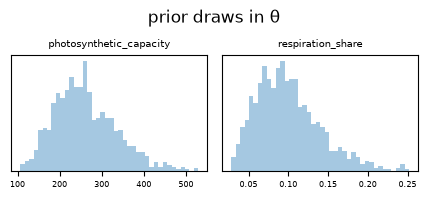

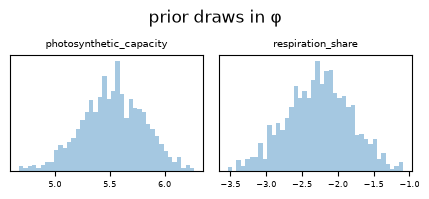

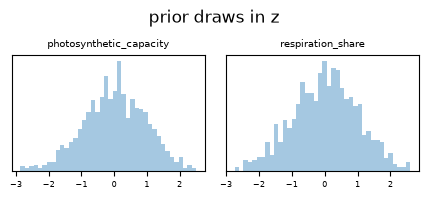

In [58]:
param_names = ["photosynthetic_capacity", "respiration_share"]
for coord, draws in {"θ": theta, "φ": phi, "z": z}.items():
    figure = plots.plot_marginals(draws[param_names], columns=2)
    figure.suptitle(f"prior draws in {coord}", y=1.08)

Since these maps are implemented as ProbPipe `Function`s, they will do the sampling for you under the hood, just as they did when we pushed distributions through the forward model.

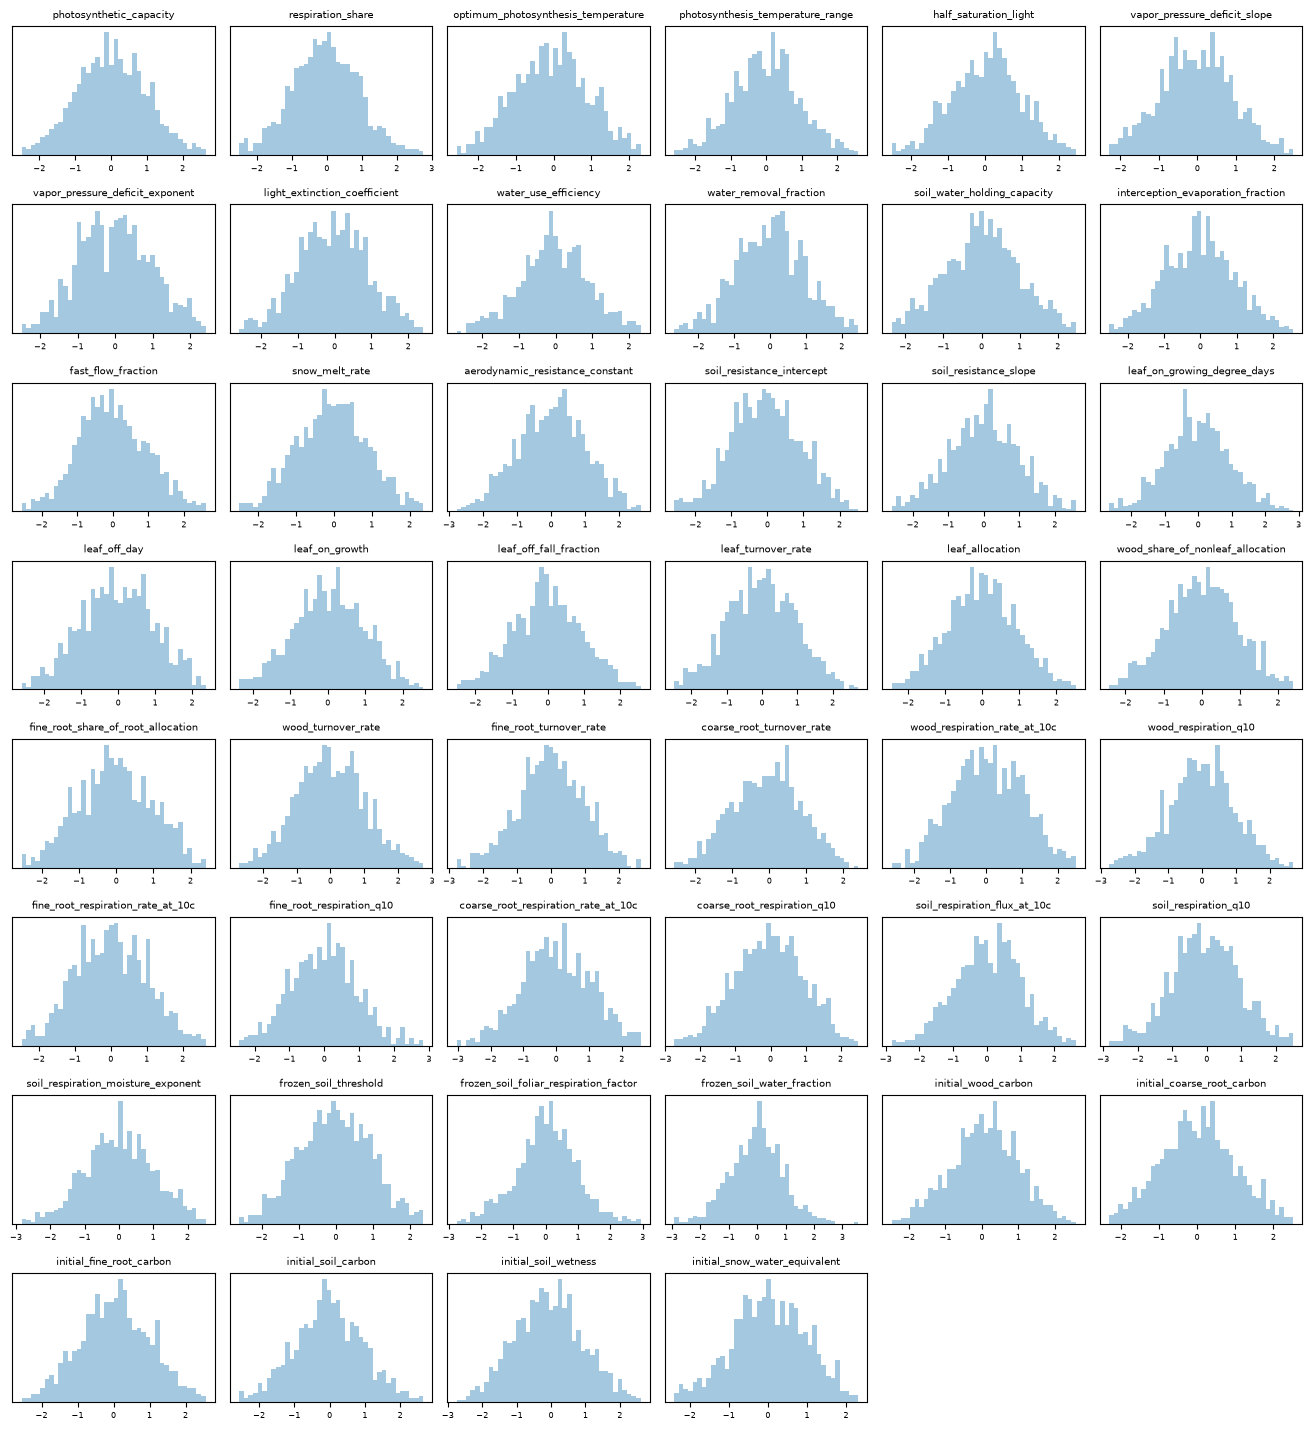

In [63]:
prior_whitened = coordinates.whiten.using(max_evaluations=1000)(prior["theta"])

plots.plot_marginals(prior_whitened);

## 9. Mathematical details

Here's the model in full for reference. 

### The posterior

With the learning rates $\eta_i$ and, when they are inferred, the noise scales $s^2_k$, the
posterior is

$$
\pi_\eta(\theta, s^2 \mid y) \;\propto\; \pi_0(\theta)\, \pi_0(s^2)
\prod_{i=1}^{n} \mathcal N\!\left(y_i \;\middle|\; G_i(\theta),\; s^2_{k(i)}\, \sigma^2_i\right)^{\eta_i},
$$

with $n = 400$ data values, $\theta \in \mathbb R^{46}$, $\sigma^2_{\mathrm{day}} = 8$,
$\sigma^2_{\mathrm{night}} = 1.5$ and, independently for each class, $s^2_k \sim \mathrm{IG}(2, 1.678)$
(that is, $1/s^2_k$ has a gamma law with shape 2 and rate 1.678). With fixed scales,
$s^2_{\mathrm{day}} = s^2_{\mathrm{night}} = 1$ and $\pi_0(s^2)$ drops out.

### From SIPNET's parameters to the calibration parameters

pySIPNET sets 58 SIPNET parameters. Twelve are fixed:

- eight have no effect on NEE at this site under SIPNET's standard model options;
- three can be changed together with others without changing NEE at all, so only the
  combinations that matter are calibrated;
- one, the initial leaf area, is zero because each run starts on 1 January, when the forest has
  no leaves.

`data.fixed_sipnet_parameters` holds their values, and `data/harvard_forest/sipnet_fixed.csv`
gives the reason for each:

In [ ]:
pd.Series(data.fixed_sipnet_parameters, name="value")

The other 46 are the calibration parameters $\theta$. Most are SIPNET parameters under the same
name. The rest change variables (in `lsmas.parameters`), so that each parameter's prior can be
stated on its own:

- **Photosynthesis.** NEE depends on SIPNET's four photosynthesis parameters only through two
  combinations, the photosynthetic capacity $P$ and the share $\rho$ of it respired by leaves.
  $P$ and $\rho$ are calibrated.
- **Photosynthesis temperatures.** The optimum $T_{\mathrm{opt}}$ and the range $\Delta$, with
  $T_{\min} = T_{\mathrm{opt}} - \Delta$, so that $T_{\min} < T_{\mathrm{opt}}$ for any values.
- **Respiration.** Each rate is stated at 10 °C, $k_{10} = k\, Q_{10}$, rather than SIPNET's
  rate $k$ at 0 °C.
- **Allocation of growth.** Leaves take a share $\ell$, wood a share $w$ of the rest, fine roots
  a share $f$ of what remains, and coarse roots the remainder; any shares in $(0, 1)$ are valid.
- **Initial pools.** The initial wood, coarse-root and fine-root carbon are each an amount, in
  g C m⁻², rather than SIPNET's total and fractions.

### The prior

$\pi_0(\theta) = \prod_{j=1}^{46} \pi_{0,j}(\theta_j)$, each factor in one of four families:

- **log-normal**, $\log \theta_j \sim \mathcal N(\mu_j, \tau_j^2)$, with $\mu_j =
  \tfrac12(\log \ell_j + \log u_j)$ and $\tau_j = (\log u_j - \log \ell_j) / (2 \times 1.96)$,
  so that $[\ell_j, u_j]$ (`lower`, `upper`) holds 95% of the probability;
- **logit-normal**, the same on the logit scale, for a parameter in $(0, 1)$;
- **normal**, with the table's `mean` and `sd`;
- **uniform** on $[\ell_j, u_j]$.

### The observation operator

SIPNET's NEE every three hours is $x(\theta) \in \mathbb R^S$, with $S = 37{,}992$ steps. Data
value $i$ averages the set $S_i$ of usable three-hour windows of its half-month and class, so

$$
A_{is} = \begin{cases} 1/|S_i| & s \in S_i, \\ 0 & \text{otherwise,} \end{cases}
\qquad G(\theta) = A\, x(\theta).
$$

### The learning rate

For class $k$, with $n_k$ values spread over $M_k$ calendar months and $c = 3$ effective
observations per class-year,

$$
\eta_k = \min\!\left(1,\; \frac{c\, M_k}{12\, n_k}\right).
$$

Computed from the data table, it matches `problem.learning_rate`:

In [ ]:
calendar_month = data.features["year"] * 12 + data.features["month"]
by_class = data.features.assign(calendar_month=calendar_month).groupby("class")
learning_rates = by_class.agg(n_k=("nee", "size"), M_k=("calendar_month", "nunique"))
learning_rates["3 M_k / (12 n_k)"] = 3 * learning_rates["M_k"] / (12 * learning_rates["n_k"])
learning_rates["problem.learning_rate"] = pd.Series(eta).groupby(data.feature_classes).first()
learning_rates

### Symbols and code

| Symbol | Meaning | In code |
|---|---|---|
| $y$ | the 400 data values | `problem.data["nee"]`, `data.features` |
| $\theta$ | the 46 calibration parameters | `problem.forward.input_spec`, `problem.coordinates.names` |
| $\pi_0(\theta)$ | the prior | `problem.prior`, `data.prior_table` |
| $x(\theta)$ | SIPNET's NEE every three hours | `SIPNETSimulator(...).nee_rate(...)` |
| $A$ | the observation operator | `data.operator` |
| $G(\theta) = A\, x(\theta)$ | the forward model | `problem.forward` |
| $\sigma^2_k$ | the noise variances | `problem.likelihood.noise_variances()` |
| $\eta$ | the learning rates | `problem.learning_rate["nee"]` |
| $\Gamma$ | the tempered noise covariance | `problem.noise_variance()` |
| $s^2_k$ | the noise scales | `load_inverse_problem("harvard_forest", scales="inferred").prior["s2"]` |
| $\phi$, $z$ | unconstrained and whitened coordinates | `problem.coordinates.unconstrain`, `problem.coordinates.whiten` |
| $\pi_\eta(\theta \mid y)$ | the posterior | `problem.condition(method=...)` |